<a href="https://colab.research.google.com/github/esra03-1/icbhi-respiratory-sound-classification/blob/main/Solunum_Seslerinden_Patoloji_Siniflandirmasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Solunum seslerindeki akustik örüntülerin sınıflandırılması
**Esra Gögebakan — CNN ve EfficientNet-B0 karşılaştırması**

Bir solunum döngüsünde ek ses bulunup bulunmadığını ve varsa türünü tahmin ediyorum:
Normal, Crackle (ral), Wheeze (hırıltı), Both (ikisi birlikte).
Bunlar hastalık tanıları değildir. Normal etiketli bir döngü, kişinin sağlıklı olduğunu göstermez.
Bu çalışma araştırma ve öğrenme amaçlıdır; klinik kullanım doğrulaması yapılmamıştır.

Akış: kurulum → anotasyonlar → hasta bazlı bölme → EDA → Log-Mel → iki model → değerlendirme → hata analizi → kayıt.

**Bu sürüm:** Kod ve açıklamalar inceleme sonrasında düzenlendi. Eski çıktılar temizlendi;
modeller yeniden eğitilmeden README'deki önceki deney sonuçları bu sürümün sonuçları sayılamaz.

## 1. Ortamı hazırlama
Colab'da **Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU** seçip hücreleri sırayla çalıştırıyorum.
İlk hücre eksik ses/veri araçlarını kurar; TensorFlow'u Colab'ın kurulu sürümünden kullanırım.
Sürümleri dosyaya kaydetmek, ortam değiştiğinde sonuçları karşılaştırmayı kolaylaştırır.
Rastgelelik tohumlarını birlikte ayarlıyorum; donanım ve kütüphane farkları nedeniyle birebir aynı sonuç yine garanti değildir.

In [1]:
%pip -q install librosa soundfile scikit-learn seaborn tqdm kaggle
import os, glob, json, sys, platform, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from IPython.display import display, Audio

SEED = 42
tf.keras.utils.set_random_seed(SEED)
os.makedirs("assets", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)
print("Python:", platform.python_version(), "TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
Path("artifacts/environment.txt").write_text(
    subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True)
)

Python: 3.13.16 TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


14161

## 2. Veriyi indirme
Kaynak: [Kaggle](https://www.kaggle.com/datasets/vbookshelf/respiratory-sound-database),
[özgün ICBHI sayfası](https://bhichallenge.med.auth.gr/).
Veri yaklaşık 3,7 GB sıkıştırılmıştır; açılması ek disk alanı ister.
Kaggle hesabımdan aldığım `kaggle.json` dosyasını yalnızca çalışma oturumuna yüklerim.
Bu dosya erişim bilgisi içerdiği için içeriğini yazdırmam ve GitHub'a eklemem.
Veri ve ön eğitimli ImageNet ağırlıkları ilk çalışmada internet gerektirir.
Verinin kullanım koşulları özgün kaynaktan ayrıca kontrol edilmelidir; kod lisansı veriyi kapsamaz.

In [2]:
from google.colab import files
from zipfile import ZipFile
import shutil

kimlik_yolu = Path.home() / ".kaggle" / "kaggle.json"
if not kimlik_yolu.exists():
    yuklenen = files.upload()
    if "kaggle.json" not in yuklenen:
        raise ValueError("Kaggle'dan aldığınız kaggle.json dosyasını seçin.")
    kimlik_yolu.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile("kaggle.json", kimlik_yolu)
    kimlik_yolu.chmod(0o600)
    Path("kaggle.json").unlink(missing_ok=True)
    del yuklenen

veri_klasoru = Path("data")
if not list(veri_klasoru.rglob("*.wav")):
    subprocess.run(["kaggle", "datasets", "download", "-d",
                    "vbookshelf/respiratory-sound-database"], check=True)
    with ZipFile("respiratory-sound-database.zip") as arsiv:
        arsiv.extractall(veri_klasoru)

adaylar = sorted({p.parent.resolve() for p in veri_klasoru.rglob("*.wav")})
if not adaylar:
    raise FileNotFoundError("Veri klasöründe .wav bulunamadı.")
# Bazı paketlerde aynı veri iki klasörde bulunur; yalnızca birini seçiyorum.
audio_dir = str(max(adaylar, key=lambda d: len(list(d.glob("*.wav")))))
print("Seçilen ses klasörü:", audio_dir)

Saving kaggle.json to kaggle.json
Seçilen ses klasörü: /content/data/Respiratory_Sound_Database/Respiratory_Sound_Database/audio_and_txt_files


## 3. Anotasyonlardan döngü tablosu oluşturma
Bir WAV kaydı birden fazla nefes döngüsü içerir. Eşleşen TXT dosyasındaki her satır
başlangıç, bitiş, crackle ve wheeze bilgisini verir; tabloya bir döngü olarak eklenir.
`(0,0) → Normal`, `(1,0) → Crackle`, `(0,1) → Wheeze`, `(1,1) → Both`.
Dosya adından hasta, göğüs bölgesi ve cihazı çıkarırım.
Eksik dosyayı sessizce atlamak yerine hata veririm; geçersiz süreleri ayrıca kaydederim.

In [3]:
# 2. Anotasyon dosyalarını okuyup 6.898 solunum döngüsünü tablo haline getirme
txt_files = sorted(glob.glob(os.path.join(audio_dir, "*.txt")))

records = []
for txt_path in txt_files:
    base_name = os.path.basename(txt_path).replace(".txt", "")
    wav_path = os.path.join(audio_dir, base_name + ".wav")
    if not os.path.exists(wav_path):
        raise FileNotFoundError(wav_path)

    # Dosya adından meta bilgileri ayıkla (Örn: 101_1b1_Al_sc_Meditron)
    parts = base_name.split("_")
    patient_id = parts[0]
    chest_loc = parts[2]
    equipment = parts[4]

    if len(parts) != 5:
        raise ValueError(f"Beklenmeyen dosya adı: {base_name}")

    ann = pd.read_csv(txt_path, sep="\t", names=["start", "end", "crackles", "wheezes"])
    for idx, row in ann.iterrows():
        if row.isna().any() or row["crackles"] not in (0, 1) or row["wheezes"] not in (0, 1):
            raise ValueError(f"Geçersiz anotasyon: {txt_path}, satır {idx}")
        c, w = int(row["crackles"]), int(row["wheezes"])
        if c == 0 and w == 0:
            label = "Normal"
        elif c == 1 and w == 0:
            label = "Crackle"
        elif c == 0 and w == 1:
            label = "Wheeze"
        else:
            label = "Both"

        records.append({
            "cycle_id": f"{base_name}:{idx}",
            "patient_id": patient_id,
            "chest_loc": chest_loc,
            "equipment": equipment,
            "wav_path": wav_path,
            "start": row["start"],
            "end": row["end"],
            "duration": row["end"] - row["start"],
            "label": label
        })

df_cycles = pd.DataFrame(records)
print(f"Toplam solunum döngüsü: {len(df_cycles)}")
print(f"Toplam benzersiz hasta sayısı: {df_cycles['patient_id'].nunique()}")
print("\nSınıf Dağılımı:\n", df_cycles["label"].value_counts())
if df_cycles.empty:
    raise ValueError("Anotasyon bulunamadı.")
assert df_cycles["cycle_id"].is_unique
gecerli = (df_cycles["start"] >= 0) & (df_cycles["duration"] >= 0.2)
df_cycles.loc[~gecerli].to_csv("artifacts/excluded_cycles.csv", index=False)
df_clean = df_cycles.loc[gecerli].reset_index(drop=True)
print(f"Ham: {len(df_cycles)} | Kullanılan: {len(df_clean)} | Elenen: {(~gecerli).sum()}")

Toplam solunum döngüsü: 6898
Toplam benzersiz hasta sayısı: 126

Sınıf Dağılımı:
 label
Normal     3642
Crackle    1864
Wheeze      886
Both        506
Name: count, dtype: int64
Ham: 6898 | Kullanılan: 6897 | Elenen: 1


## 4. Hasta bazlı bölme ve kontroller
Aynı kişinin döngüleri birbirine benzeyebilir. Döngüleri rastgele ayırırsam model yeni bir kişiye
genellemek yerine kişiye özgü sesi öğrenebilir. Bu nedenle `patient_id` ile gruplarım.
`GroupShuffleSplit` oranları **hasta gruplarına** uygular; döngü oranları tam %70/%15/%15 olmak zorunda değildir.
Bu özel bir rastgele hasta bölmesidir, resmi ICBHI challenge bölmesi değildir.

Bölmeyi pencere seçimi ve eğitimden önce yaparım. Sınıf dağılımlarını ve hasta kesişimlerini kontrol ederim.
Bir sınıf eksikse test sonucuna bakarak tekrar tekrar tohum seçmek yerine bölme protokolünü yeniden tasarlamak gerekir.
Test kümesi eğitim ayarlarını seçmek için kullanılmaz.

In [4]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils.class_weight import compute_class_weight

label_map = {"Normal": 0, "Crackle": 1, "Wheeze": 2, "Both": 3}
class_names = list(label_map)
y = df_clean["label"].map(label_map).to_numpy(dtype=np.int32)
groups = df_clean["patient_id"].to_numpy()
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss1.split(df_clean, y, groups))
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
val_local, test_local = next(gss2.split(df_clean.iloc[temp_idx], y[temp_idx], groups[temp_idx]))
val_idx, test_idx = temp_idx[val_local], temp_idx[test_local]

train_meta = df_clean.iloc[train_idx].reset_index(drop=True)
val_meta = df_clean.iloc[val_idx].reset_index(drop=True)
test_meta = df_clean.iloc[test_idx].reset_index(drop=True)
hasta_kumeleri = [set(t["patient_id"]) for t in (train_meta, val_meta, test_meta)]
assert not (hasta_kumeleri[0] & hasta_kumeleri[1])
assert not (hasta_kumeleri[0] & hasta_kumeleri[2])
assert not (hasta_kumeleri[1] & hasta_kumeleri[2])
assert len(train_meta) + len(val_meta) + len(test_meta) == len(df_clean)

ozetler = []
for ad, tablo in [("train", train_meta), ("validation", val_meta), ("test", test_meta)]:
    sayilar = tablo["label"].value_counts().reindex(class_names, fill_value=0)
    if (sayilar == 0).any():
        raise ValueError(f"{ad} kümesinde eksik sınıf var: {sayilar.to_dict()}")
    ozetler.append({"Küme": ad, "Hasta": tablo.patient_id.nunique(),
                     "Döngü": len(tablo), **sayilar.to_dict()})
    tablo.assign(split=ad).to_csv(f"artifacts/{ad}_manifest.csv", index=False)
display(pd.DataFrame(ozetler))

,Küme,Hasta,Döngü,Normal,Crackle,Wheeze,Both
0,train,88,4915,2597,1323,655,340
1,validation,19,990,485,354,83,68
2,test,19,992,559,187,148,98


## 5. Veri keşfi: sınıflar, cihazlar, süreler, ses örnekleri
Üç farklı açıdan bakıyorum: sınıf dengesizliği, cihaz-sınıf ilişkisi ve süre dağılımı.
Aşağıdaki grafiklerde **yalnızca eğitim kümesini** kullanıyorum; pencere ve ön işleme tercihlerini testten öğrenmiyorum.
Cihaz-sınıf ilişkisinin güçlü olması, modelin ses örüntüsü yerine cihaz özelliklerinden yararlanması riskini düşündürür;
bu grafik tek başına böyle bir durumun gerçekleştiğini kanıtlamaz.

Dalga formunda yatay eksen zaman, dikey eksen genliktir. Spektrogramda yatay eksen zaman,
dikey eksen frekans, renk enerji düzeyidir. Mel ölçeği frekansı insan işitmesine yakın biçimde düzenler;
logaritmik dB dönüşümü güçlü ve zayıf bileşenleri birlikte görmeyi kolaylaştırır.

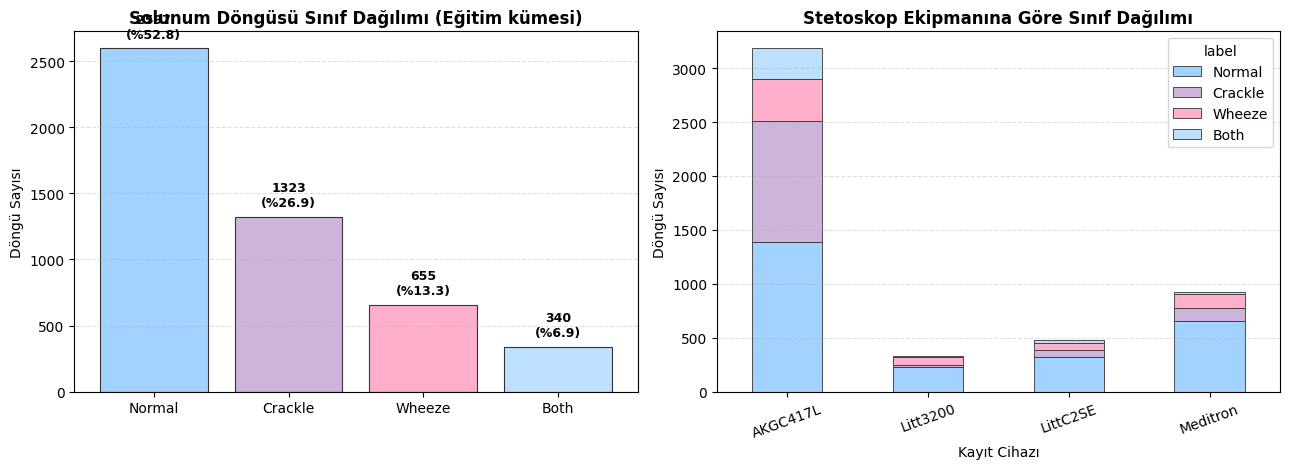

Süre Özeti -> Ortalama: 2.69 sn | Medyan: 2.54 sn | %90 Yüzdelik: 4.06 sn


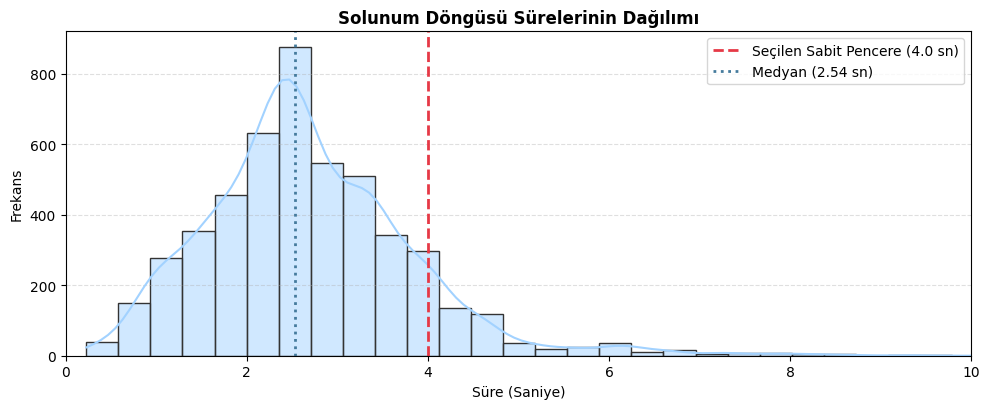

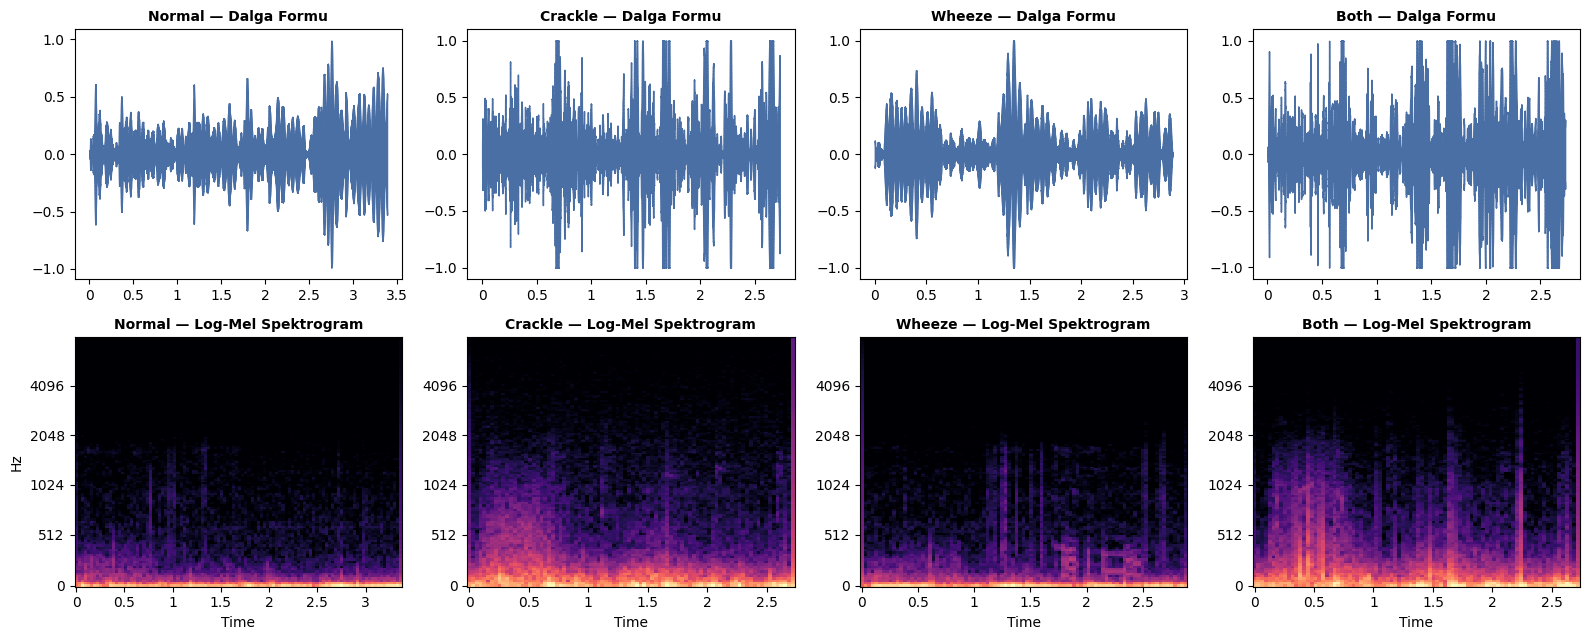

In [5]:
# Eğitim kümesinde keşifçi analiz
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display

os.makedirs("assets", exist_ok=True)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"

palette = ["#a2d2ff", "#cdb4db", "#ffafcc", "#bde0fe"]
order = ["Normal", "Crackle", "Wheeze", "Both"]

# --- GRAFİK 1: Sınıf Dağılımı ve Kayıt Cihazı Analizi ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

counts = train_meta["label"].value_counts().reindex(order)
bars = axes[0].bar(counts.index, counts.values, color=palette, edgecolor="#333333", linewidth=0.8)
axes[0].set_title("Solunum Döngüsü Sınıf Dağılımı (Eğitim kümesi)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Döngü Sayısı")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 60, f"{h}\n(%{h/len(train_meta)*100:.1f})",
                 ha="center", va="bottom", fontsize=9, fontweight="bold")

ct = pd.crosstab(train_meta["equipment"], train_meta["label"])[order]
ct.plot(kind="bar", stacked=True, ax=axes[1], color=palette, edgecolor="#333333", linewidth=0.6)
axes[1].set_title("Stetoskop Ekipmanına Göre Sınıf Dağılımı", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Kayıt Cihazı")
axes[1].set_ylabel("Döngü Sayısı")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("assets/fig1_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 2: Solunum Döngüsü Süreleri (Duration) ---
print(f"Süre Özeti -> Ortalama: {train_meta['duration'].mean():.2f} sn | "
      f"Medyan: {train_meta['duration'].median():.2f} sn | "
      f"%90 Yüzdelik: {np.percentile(train_meta['duration'], 90):.2f} sn")

plt.figure(figsize=(10, 4.2))
sns.histplot(data=train_meta, x="duration", bins=45, kde=True, color="#a2d2ff", edgecolor="#333333")
plt.axvline(4.0, color="#e63946", linestyle="--", linewidth=2, label="Seçilen Sabit Pencere (4.0 sn)")
plt.axvline(train_meta["duration"].median(), color="#457b9d", linestyle=":", linewidth=2,
            label=f"Medyan ({train_meta['duration'].median():.2f} sn)")
plt.title("Solunum Döngüsü Sürelerinin Dağılımı", fontsize=12, fontweight="bold")
plt.xlabel("Süre (Saniye)")
plt.ylabel("Frekans")
plt.xlim(0, 10)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("assets/fig2_duration_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 3: 4 Sınıf İçin Waveform & Log-Mel Spectrogram Karşılaştırması ---
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
sr_eda = 16000

for i, lbl in enumerate(order):
    sample = train_meta[(train_meta["label"] == lbl) & (train_meta["duration"] >= 2.5)].iloc[0]
    y, _ = librosa.load(sample["wav_path"], sr=sr_eda,
                        offset=sample["start"], duration=min(4.0, sample["duration"]))

    # Üst satır: Waveform
    librosa.display.waveshow(y, sr=sr_eda, ax=axes[0, i], color="#4a6fa5")
    axes[0, i].set_title(f"{lbl} — Dalga Formu", fontsize=10, fontweight="bold")
    axes[0, i].set_xlabel("")
    if i > 0:
        axes[0, i].set_ylabel("")

    # Alt satır: Log-Mel Spectrogram
    mel_spec = librosa.feature.melspectrogram(y=y, sr=sr_eda, n_mels=128, n_fft=1024, hop_length=512)
    log_mel = librosa.power_to_db(mel_spec, ref=np.max)
    img = librosa.display.specshow(log_mel, sr=sr_eda, hop_length=512, x_axis="time", y_axis="mel",
                                   ax=axes[1, i], cmap="magma")
    axes[1, i].set_title(f"{lbl} — Log-Mel Spektrogram", fontsize=10, fontweight="bold")
    if i > 0:
        axes[1, i].set_ylabel("")

plt.tight_layout()
plt.savefig("assets/fig3_waveform_spectrogram.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. Sesleri Log-Mel tensörüne dönüştürme
`16.000 Hz`, saniyede 16.000 örnek demektir. Yeniden örnekleme ortak bir zaman çözünürlüğü sağlar;
cihazların frekans yanıtlarını veya gürültüsünü eşitlemez.
Bu karşılaştırmada 4 saniyelik pencereyi sabit deney ayarı olarak koruyorum; yeni bir seçim yapacaksam eğitim
süre dağılımıyla gerekçelendireceğim. Kısa sesler sıfırla doldurulur, uzun seslerin ilk 4 saniyesi alınır.
Kırpma sondaki önemli sesi kaybettirebilir; dolgu da yapay bir sınır oluşturabilir.

`n_fft=1024` yaklaşık 64 ms analiz penceresi, `hop_length=512` yaklaşık 32 ms kayma,
`n_mels=128` ise 128 frekans bandıdır. `center=True` ile 64.000 örnekten 126 zaman çerçevesi çıkar.
Her spektrogram kendi minimum ve maksimumuyla [0,1]'e dönüştürülür; bu işlem başka hastalardan
istatistik öğrenmez, ancak mutlak ses şiddeti bilgisini azaltır.
Üç kanal aynı matrisin kopyasıdır; gerçek renk veya ek akustik bilgi içermez.

In [6]:
from tqdm.auto import tqdm
TARGET_SR = 16000
TARGET_DURATION = 4.0
TARGET_SAMPLES = int(TARGET_SR * TARGET_DURATION)
N_MELS, N_FFT, HOP_LENGTH = 128, 1024, 512

def sesi_spektrograma_cevir(clip):
    if len(clip) == 0 or not np.isfinite(clip).all():
        raise ValueError("Boş veya geçersiz ses döngüsü.")
    clip = librosa.util.fix_length(clip, size=TARGET_SAMPLES)
    mel = librosa.feature.melspectrogram(
        y=clip, sr=TARGET_SR, n_mels=N_MELS, n_fft=N_FFT,
        hop_length=HOP_LENGTH, center=True)
    log_mel = librosa.power_to_db(mel, ref=np.max)
    norm = (log_mel - log_mel.min()) / (np.ptp(log_mel) + 1e-8)
    return np.repeat(norm[..., None], 3, axis=-1).astype(np.float32)

def veriyi_hazirla(tablo):
    # Önceden yer ayırarak liste + dizi kopyalarının RAM maliyetini azaltıyorum.
    veri = np.empty((len(tablo), N_MELS, 126, 3), dtype=np.float32)
    for wav_path, satirlar in tqdm(tablo.groupby("wav_path"), desc="Sesler işleniyor"):
        ses, _ = librosa.load(wav_path, sr=TARGET_SR)
        for idx, row in satirlar.iterrows():
            if row["end"] > len(ses) / TARGET_SR + 0.02:
                raise ValueError(f"Anotasyon ses süresini aşıyor: {row['cycle_id']}")
            clip = ses[int(row["start"] * TARGET_SR):int(row["end"] * TARGET_SR)]
            veri[idx] = sesi_spektrograma_cevir(clip)
    assert np.isfinite(veri).all() and veri.min() >= 0 and veri.max() <= 1.000001
    etiketler = tablo["label"].map(label_map).to_numpy(dtype=np.int32)
    return veri, etiketler

X_train, y_train = veriyi_hazirla(train_meta)
X_val, y_val = veriyi_hazirla(val_meta)
X_test, y_test = veriyi_hazirla(test_meta)
classes = np.arange(4)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weights = dict(zip(classes.tolist(), weights.astype(float).tolist()))
print("Tensörler:", X_train.shape, X_val.shape, X_test.shape)
print("Sınıf ağırlıkları:", class_weights)
for ad, tablo in [("train", train_meta), ("validation", val_meta), ("test", test_meta)]:
    print(ad, "dolgu gereken oran:", (tablo.duration < TARGET_DURATION).mean(),
          "kırpılan oran:", (tablo.duration > TARGET_DURATION).mean())

Sesler işleniyor:   0%|          | 0/677 [00:00<?, ?it/s]

Sesler işleniyor:   0%|          | 0/117 [00:00<?, ?it/s]

Sesler işleniyor:   0%|          | 0/126 [00:00<?, ?it/s]

Tensörler: (4915, 128, 126, 3) (990, 128, 126, 3) (992, 128, 126, 3)
Sınıf ağırlıkları: {0: 0.47314208702348864, 1: 0.9287603930461074, 2: 1.8759541984732824, 3: 3.613970588235294}
train dolgu gereken oran: 0.8921668362156663 kırpılan oran: 0.10783316378433368
validation dolgu gereken oran: 0.7909090909090909 kırpılan oran: 0.20909090909090908
test dolgu gereken oran: 0.9435483870967742 kırpılan oran: 0.05443548387096774


## 7. Baseline: sıfırdan öğrenen 2D-CNN
Dört Conv2D bloğu yerel zaman-frekans örüntülerini öğrenir; filtre sayıları 32, 64, 128, 256'dır.
**İlk üç blokta** MaxPooling vardır; son bloktan sonra GlobalAveragePooling kullanılır.
BatchNormalization eğitimdeki aktivasyon dağılımlarını düzenler; Dropout ezberlemeyi azaltmayı hedefler.
Son Dense katmanının dört softmax çıktısı sınıf skorlarıdır; yüksek skor doğruluk garantisi değildir.

Tam sayı etiketler için sparse categorical cross-entropy ve Adam kullanıyorum.
`class_weight`, az görülen sınıfların eğitim kaybındaki etkisini artırır; veri sayısını eşitlemez.
Doğrulama kaybıyla en iyi ağırlığı seçiyorum. Bu ölçüt Macro F1 ile aynı değildir;
ileride Macro F1 ile seçim ayrı ve önceden tanımlanmış bir deney olarak yapılabilir.
Ağırlıklandırılmış eğitim kaybı ile ağırlıklandırılmamış doğrulama kaybının düzeyleri doğrudan karşılaştırılmamalıdır.

In [7]:
# Adım 4: Baseline 2D-CNN Modelinin Kurulması ve Eğitilmesi
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(SEED)

def build_baseline_cnn(input_shape=(128, 126, 3), num_classes=4):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        # Blok 1
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 2
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 3
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Blok 4
        layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling2D(),

        # Sınıflandırıcı Başlık
        layers.Dropout(0.4),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(num_classes, activation="softmax")
    ], name="Baseline_2D_CNN")

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_cnn()
baseline_model.summary()

cb_baseline = [
    callbacks.ModelCheckpoint("artifacts/baseline_best.weights.h5", monitor="val_loss", save_best_only=True, save_weights_only=True),
    callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]

history_baseline = baseline_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=cb_baseline,
    verbose=1
)
baseline_model.load_weights("artifacts/baseline_best.weights.h5")

Model: "Baseline_2D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 63, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 31, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 31, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 15, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 15, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 15, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,748 (1.62 MB)

 Trainable params: 422,788 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 39s 146ms/step - accuracy: 0.3278 - loss: 1.3871 - val_accuracy: 0.4455 - val_loss: 1.1234 - learning_rate: 0.0010
Epoch 2/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 9s 25ms/step - accuracy: 0.3628 - loss: 1.3104 - val_accuracy: 0.5263 - val_loss: 1.1913 - learning_rate: 0.0010
Epoch 3/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.3878 - loss: 1.2769 - val_accuracy: 0.4222 - val_loss: 1.2046 - learning_rate: 0.0010
Epoch 4/30
153/154 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4171 - loss: 1.2548
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.4094 - loss: 1.2434 - val_accuracy: 0.5030 - val_loss: 1.2959 - learning_rate: 0.0010
Epoch 5/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.4560 - loss: 1.1946 - val_accuracy: 0.5131 - val_loss: 1.1621 - learning_rate: 5.0000e-04
Epoch 6/30
154/154 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.4669 - los

## 8. EfficientNet-B0: özellik çıkarımı ve ince ayar
ImageNet ön eğitimi ses verisi üzerinde yapılmamıştır; yararlı olup olmadığını deneyle ölçüyorum.
Girişteki `Rescaling(255)` doğrudur: [0,1] girdisini Keras EfficientNet'in beklediği [0,255]'e taşır;
omurganın içindeki normalizasyon sonra uygulanır.

İlk aşamada omurga dondurulur. İkinci aşama, ilk aşamanın **en iyi** ağırlıklarıyla başlar.
Son 30 katmandaki BatchNormalization dışındaki katmanları açarım; omurgayı `training=False` ile çağırarak
ön eğitimli BN istatistiklerini korurum. Bu, açılan konvolüsyon ağırlıklarına gradyan gitmesini engellemez.
İkinci aşama doğrulama kaybını iyileştirmezse ilk aşamanın modeli korunur.
Seçimde test metriklerini kullanmam.

In [8]:
from tensorflow.keras.applications import EfficientNetB0

def build_efficientnet_model(input_shape=(128, 126, 3), num_classes=4, weights="imagenet"):
    inputs = layers.Input(shape=input_shape)
    x = layers.Rescaling(255.0)(inputs)
    base_model = EfficientNetB0(include_top=False, weights=weights, input_shape=input_shape)
    base_model.trainable = False
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs, outputs, name="EfficientNetB0_TL")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model, base_model

def egitim_kontrolleri(dosya):
    return [
        callbacks.ModelCheckpoint(dosya, monitor="val_loss", save_best_only=True, save_weights_only=True),
        callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6)
    ]

tf.keras.utils.set_random_seed(SEED)
effnet_model, base_effnet = build_efficientnet_model()
history_eff_stage1 = effnet_model.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs=8, batch_size=32,
    class_weight=class_weights,
    callbacks=egitim_kontrolleri("artifacts/effnet_stage1.weights.h5"), verbose=1)
effnet_model.load_weights("artifacts/effnet_stage1.weights.h5")

base_effnet.trainable = True
for i, layer in enumerate(base_effnet.layers):
    layer.trainable = i >= len(base_effnet.layers) - 30 and not isinstance(layer, layers.BatchNormalization)
effnet_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),
                     loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history_eff_stage2 = effnet_model.fit(
    X_train, y_train, validation_data=(X_val, y_val), epochs=22, batch_size=32,
    class_weight=class_weights,
    callbacks=egitim_kontrolleri("artifacts/effnet_stage2.weights.h5"), verbose=1)
asama1_kayip = min(history_eff_stage1.history["val_loss"])
asama2_kayip = min(history_eff_stage2.history["val_loss"])
secilen_asama = 1 if asama1_kayip <= asama2_kayip else 2
effnet_model.load_weights(f"artifacts/effnet_stage{secilen_asama}.weights.h5")
print("Doğrulama kaybıyla seçilen aşama:", secilen_asama)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 119s 491ms/step - accuracy: 0.3638 - loss: 1.7191 - val_accuracy: 0.3626 - val_loss: 1.2824 - learning_rate: 0.0010
Epoch 2/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 21ms/step - accuracy: 0.4523 - loss: 1.3401 - val_accuracy: 0.3768 - val_loss: 1.2849 - learning_rate: 0.0010
Epoch 3/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - accuracy: 0.4848 - loss: 1.2256 - val_accuracy: 0.3535 - val_loss: 1.3183 - learning_rate: 0.0010
Epoch 4/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.5095 - loss: 1.0980 - val_accuracy: 0.4051 - val_loss: 1.2522 - learning_rate: 0.0010
Epoch 5/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.5276 - loss: 1.0453 - val_accuracy: 0.3869 - val_loss: 1.2983 - learning_rate: 0.0010
Epoch 6/8
154/154 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.5438 - loss: 1.0207 - val_accuracy: 0.3707 - val_loss: 1.3476 - learning_rate: 0.0010
Epoch 7/8
154/154 ━━━━━━━━━━━━━━━━

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 14 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


## 9. Test: metrikler ve çoğunluk sınıfı referansı
Modellerin eğitim ve seçim işlemleri bitti; şimdi aynı test örneklerini kullanırım.
Accuracy doğru tahmin oranıdır. Precision, bir sınıfa verilen tahminlerin doğruluğunu;
Recall, o sınıftaki gerçek örneklerin ne kadarını bulduğumu ölçer. F1 ikisini birlikte özetler.
Macro ortalama dört sınıfa eşit ağırlık verir; çoğunluk sınıfının etkisini azaltır.
ROC-AUC eşiklerden bağımsız sıralama gücünü özetler; yüksek accuracy veya kalibre güven anlamına gelmez.

`DummyClassifier`, eğitimde en sık sınıf hangisiyse her girdiye onu söyler.
Bu basit referans accuracy ile Macro F1'in neden birlikte okunması gerektiğini gösterir.
Karışıklık matrisinde satır gerçek, sütun tahmindir; satırdaki yüzdeler Recall dağılımını gösterir.
Tek bir hasta bölmesindeki küçük farklar istatistiksel üstünlük veya klinik güvenilirlik kanıtı değildir.

=== TEST SETİ MODEL KARŞILAŞTIRMA TABLOSU ===


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1-Score,ROC-AUC (OvR)
0,Çoğunluk sınıfı referansı,0.5635,0.1409,0.250,0.1802,0.5000
1,Baseline 2D-CNN,0.4869,0.3795,0.355,0.3411,0.7141
2,EfficientNet-B0 (TL),0.4254,0.3466,0.364,0.3483,0.6597



--- Baseline 2D-CNN Sınıf Bazlı Rapor ---
              precision    recall  f1-score   support

      Normal       0.72      0.63      0.67       559
     Crackle       0.26      0.53      0.35       187
      Wheeze       0.35      0.13      0.19       148
        Both       0.19      0.13      0.15        98

    accuracy                           0.49       992
   macro avg       0.38      0.36      0.34       992
weighted avg       0.53      0.49      0.49       992


--- EfficientNet-B0 (Transfer Learning) Sınıf Bazlı Rapor ---
              precision    recall  f1-score   support

      Normal       0.68      0.51      0.58       559
     Crackle       0.28      0.34      0.31       187
      Wheeze       0.18      0.24      0.21       148
        Both       0.25      0.36      0.29        98

    accuracy                           0.43       992
   macro avg       0.35      0.36      0.35       992
weighted avg       0.49      0.43      0.45       992



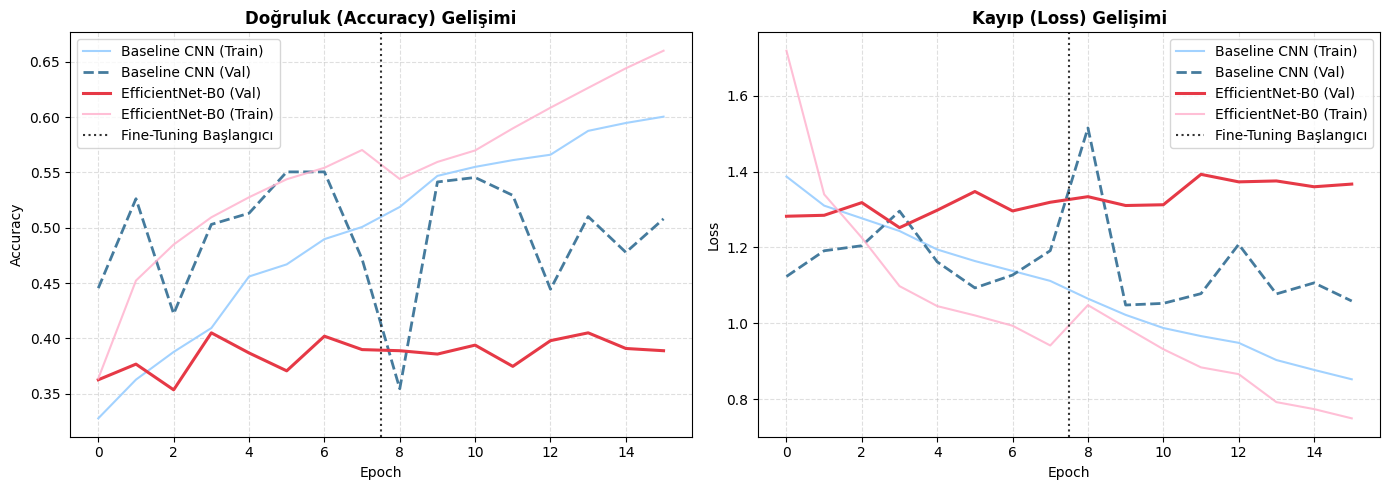

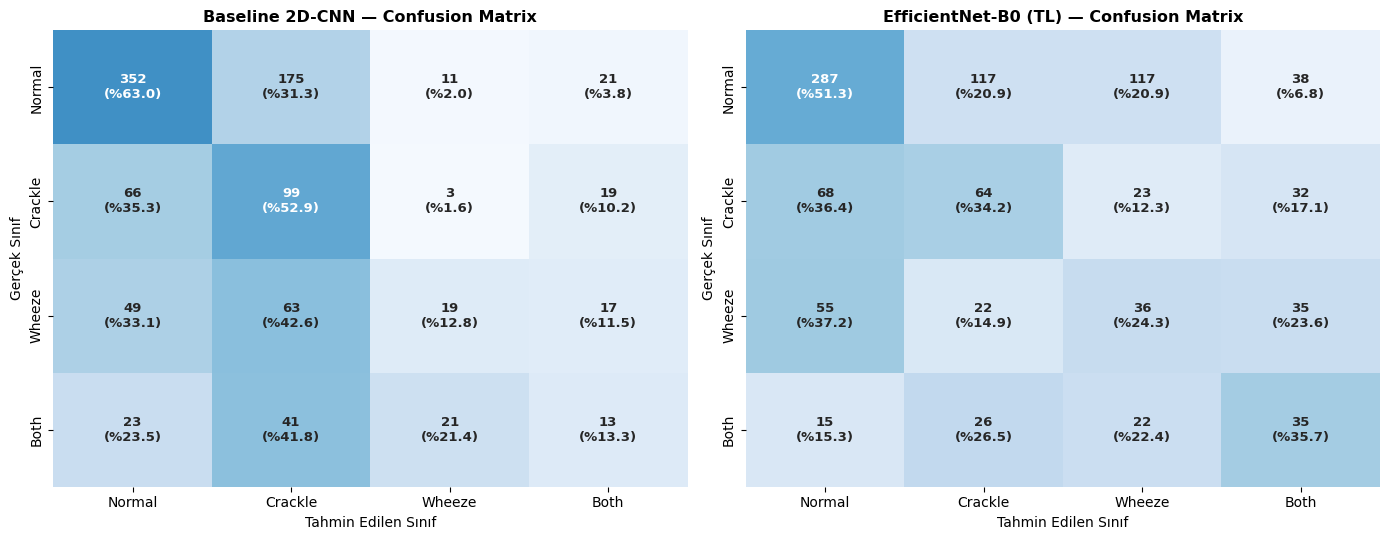

In [9]:
# Adım 6: Test Seti Performans Karşılaştırması, Eğitim Eğrileri ve Confusion Matrix
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix
)

class_names = ["Normal", "Crackle", "Wheeze", "Both"]

from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
dummy_pred = dummy.predict(np.zeros((len(y_test), 1)))
dummy_prob = dummy.predict_proba(np.zeros((len(y_test), 1)))

# Test seti tahminleri
y_prob_base = baseline_model.predict(X_test, verbose=0)
y_pred_base = np.argmax(y_prob_base, axis=1)

y_prob_eff = effnet_model.predict(X_test, verbose=0)
y_pred_eff = np.argmax(y_prob_eff, axis=1)

def get_metrics(y_true, y_pred, y_prob, model_name):
    return {
        "Model": model_name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Macro Precision": round(precision_score(y_true, y_pred, average="macro", labels=np.arange(4), zero_division=0), 4),
        "Macro Recall": round(recall_score(y_true, y_pred, average="macro", labels=np.arange(4), zero_division=0), 4),
        "Macro F1-Score": round(f1_score(y_true, y_pred, average="macro", labels=np.arange(4), zero_division=0), 4),
        "ROC-AUC (OvR)": round(roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"), 4)
    }

df_results = pd.DataFrame([
    get_metrics(y_test, dummy_pred, dummy_prob, "Çoğunluk sınıfı referansı"),
    get_metrics(y_test, y_pred_base, y_prob_base, "Baseline 2D-CNN"),
    get_metrics(y_test, y_pred_eff, y_prob_eff, "EfficientNet-B0 (TL)")
])

print("=== TEST SETİ MODEL KARŞILAŞTIRMA TABLOSU ===")
display(df_results)

print("\n--- Baseline 2D-CNN Sınıf Bazlı Rapor ---")
print(classification_report(y_test, y_pred_base, labels=np.arange(4), target_names=class_names, zero_division=0))

print("\n--- EfficientNet-B0 (Transfer Learning) Sınıf Bazlı Rapor ---")
print(classification_report(y_test, y_pred_eff, labels=np.arange(4), target_names=class_names, zero_division=0))

# --- GRAFİK 4: Eğitim ve Doğrulama Eğrileri ---
eff_acc = history_eff_stage1.history["accuracy"] + history_eff_stage2.history["accuracy"]
eff_val_acc = history_eff_stage1.history["val_accuracy"] + history_eff_stage2.history["val_accuracy"]
eff_loss = history_eff_stage1.history["loss"] + history_eff_stage2.history["loss"]
eff_val_loss = history_eff_stage1.history["val_loss"] + history_eff_stage2.history["val_loss"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy Eğrisi
axes[0].plot(history_baseline.history["accuracy"], label="Baseline CNN (Train)", color="#a2d2ff")
axes[0].plot(history_baseline.history["val_accuracy"], label="Baseline CNN (Val)", linestyle="--", color="#457b9d", linewidth=2)
axes[0].plot(eff_val_acc, label="EfficientNet-B0 (Val)", color="#e63946", linewidth=2.2)
axes[0].plot(eff_acc, label="EfficientNet-B0 (Train)", color="#ffafcc", alpha=0.8)
axes[0].axvline(len(history_eff_stage1.history["loss"]) - 0.5, color="#333333", linestyle=":", label="Fine-Tuning Başlangıcı")
axes[0].set_title("Doğruluk (Accuracy) Gelişimi", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.4)

# Loss Eğrisi
axes[1].plot(history_baseline.history["loss"], label="Baseline CNN (Train)", color="#a2d2ff")
axes[1].plot(history_baseline.history["val_loss"], label="Baseline CNN (Val)", linestyle="--", color="#457b9d", linewidth=2)
axes[1].plot(eff_val_loss, label="EfficientNet-B0 (Val)", color="#e63946", linewidth=2.2)
axes[1].plot(eff_loss, label="EfficientNet-B0 (Train)", color="#ffafcc", alpha=0.8)
axes[1].axvline(len(history_eff_stage1.history["loss"]) - 0.5, color="#333333", linestyle=":", label="Fine-Tuning Başlangıcı")
axes[1].set_title("Kayıp (Loss) Gelişimi", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("assets/fig4_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

# --- GRAFİK 5: Yan Yana Confusion Matrix ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, y_pred, title in zip(
    axes,
    [y_pred_base, y_pred_eff],
    ["Baseline 2D-CNN — Confusion Matrix", "EfficientNet-B0 (TL) — Confusion Matrix"]
):
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(4))
    cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm[i, j]}\n(%{cm_norm[i, j]:.1f})"

    sns.heatmap(cm_norm, annot=annot, fmt="", cmap="Blues", xticklabels=class_names,
                yticklabels=class_names, cbar=False, ax=ax, vmin=0, vmax=100,
                annot_kws={"size": 9.5, "weight": "bold"})
    ax.set_title(title, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Tahmin Edilen Sınıf")
    ax.set_ylabel("Gerçek Sınıf")

plt.tight_layout()
plt.savefig("assets/fig5_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()
df_results.to_csv("artifacts/model_comparison.csv", index=False)
for ad, tahmin, olasilik in [("baseline", y_pred_base, y_prob_base), ("efficientnet", y_pred_eff, y_prob_eff)]:
    tablo = test_meta.copy()
    tablo["true_id"] = y_test
    tablo["pred_id"] = tahmin
    for i, sinif in enumerate(class_names):
        tablo[f"prob_{sinif}"] = olasilik[:, i]
    tablo.to_csv(f"artifacts/{ad}_test_predictions.csv", index=False)
    rapor = classification_report(y_test, tahmin, labels=np.arange(4), target_names=class_names,
                                  zero_division=0, output_dict=True)
    Path(f"artifacts/{ad}_classification_report.json").write_text(json.dumps(rapor, indent=2))

## 10. Hata analizi: gözlem ile açıklamayı ayırma
En yüksek softmax skoruyla yapılan yanlış tahminleri çiziyorum. Bu dört örnek bütün test hatalarını temsil etmez.
Siyah dolgu alanı gözlemlenebilir; **hataların nedeni dolgudur** sonucuna tek başına ulaşamam.
Sürtünme gürültüsü iddiası için sesi dinlemek; dolgu etkisi için aynı bölmede tek değişkenli karşılaştırma yapmak gerekir.
Aşağıda örnek kimliklerini, sürelerini ve tahminlerini kaydeder; tüm test kümesinde süre ve cihaz bazlı hata oranlarını gösteririm.
Bu gruplar birbirinden bağımsız değildir ve az örnekli grupların oranları kararsız olabilir.

Buradaki analizden doğan yeni fikirleri eğitim/doğrulama üzerinde sınayacağım.
Bu test kümesi artık incelendiği için ileride bağımsız bir nihai değerlendirme veya grup çapraz doğrulaması gerekecektir.

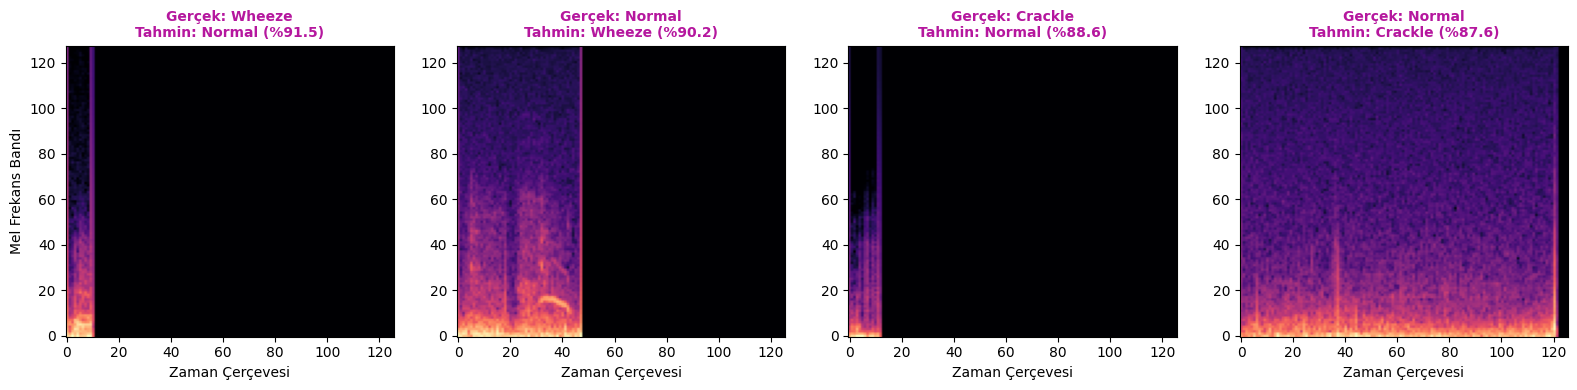

,cycle_id,duration,gercek,tahmin,skor
723,192_2b2_Ar_mc_LittC2SE:7,0.300,2,0,0.914751
484,178_1b2_Ar_mc_AKGC417L:3,1.500,0,2,0.902444
114,132_2b2_Lr_mc_LittC2SE:9,0.367,1,0,0.886036
150,145_2b2_Pr_mc_AKGC417L:3,3.857,0,1,0.876468


,ornek,hasta,hata_orani
sure_grubu,,,
0–1.5 sn,203,17,0.37931
1.5–4 sn,735,19,0.62449
4+ sn,54,7,0.62963


,ornek,hasta,hata_orani
equipment,,,
AKGC417L,743,7,0.600269
Litt3200,50,1,0.340000
LittC2SE,65,2,0.815385
Meditron,134,9,0.402985


In [10]:
# Adım 7: En Yüksek Güven Skorlu 4 Yanlış Tahminin Spektrogram Analizi
mis_indices = np.where(y_pred_eff != y_test)[0]
confidences = np.max(y_prob_eff[mis_indices], axis=1)
top_error_idx = mis_indices[np.argsort(confidences)[::-1][:4]]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax in axes:
    ax.set_visible(False)
for i, idx in enumerate(top_error_idx):
    axes[i].set_visible(True)
    spec_2d = X_test[idx, :, :, 0]
    true_lbl = class_names[y_test[idx]]
    pred_lbl = class_names[y_pred_eff[idx]]
    conf = np.max(y_prob_eff[idx]) * 100

    axes[i].imshow(spec_2d, aspect="auto", origin="lower", cmap="magma")
    axes[i].set_title(f"Gerçek: {true_lbl}\nTahmin: {pred_lbl} (%{conf:.1f})",
                      fontsize=10, fontweight="bold", color="#b5179e")
    axes[i].set_xlabel("Zaman Çerçevesi")
    if i == 0:
        axes[i].set_ylabel("Mel Frekans Bandı")

plt.tight_layout()
plt.savefig("assets/fig6_error_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


hata_tablosu = test_meta.assign(
    gercek=y_test, tahmin=y_pred_eff, hata=(y_pred_eff != y_test),
    skor=y_prob_eff.max(axis=1))
display(hata_tablosu.iloc[top_error_idx][["cycle_id", "duration", "gercek", "tahmin", "skor"]])
hata_tablosu["sure_grubu"] = pd.cut(hata_tablosu.duration, [0, 1.5, 4, np.inf],
                                    labels=["0–1.5 sn", "1.5–4 sn", "4+ sn"])
for sutun in ["sure_grubu", "equipment"]:
    ozet = hata_tablosu.groupby(sutun, observed=True).agg(
        ornek=("hata", "size"), hasta=("patient_id", "nunique"), hata_orani=("hata", "mean"))
    display(ozet)
    ozet.to_csv(f"artifacts/errors_by_{sutun}.csv")

# Bir örneği dinlemek için aşağıdaki iki satırın başındaki # işaretini kaldırabilirim.
# ornek = hata_tablosu.iloc[top_error_idx[0]]
# display(Audio(filename=ornek["wav_path"]))  # Tam WAV kaydını çalar; tek döngü değildir.

## 11. Deneyi kaydetme ve yeni bir döngüye tahmin üretme
Colab oturumu kapanınca bellekteki modeller kaybolur; iki modeli `.keras` biçiminde kaydederim.
Etiket haritası, ön işleme ayarları, eğitim geçmişleri ve bölme dosyaları da deneyin parçasıdır.
Aşağıdaki fonksiyon **başlangıç ve bitişi önceden bilinen bir döngüyü** sınıflandırır;
uzun bir kayıtta döngü tespiti yapmaz. Tahmin skoru tanı olasılığı olarak yorumlanamaz.
Model seçimi ve yeni deneylerin sonuçları rapora ancak gerçekten çalıştırıldıktan sonra aktarılmalıdır.

In [11]:
baseline_model.save("artifacts/baseline.keras")
effnet_model.save("artifacts/efficientnet.keras")
config = {"sample_rate": TARGET_SR, "duration": TARGET_DURATION,
          "n_mels": N_MELS, "n_fft": N_FFT, "hop_length": HOP_LENGTH,
          "center": True, "normalization": "per_spectrogram_minmax",
          "padding": "zero_right", "crop": "first_4_seconds",
          "label_map": label_map, "seed": SEED, "selected_effnet_stage": secilen_asama,
          "class_weights": class_weights}
Path("artifacts/config.json").write_text(json.dumps(config, indent=2))
for ad, gecmis in [("baseline", history_baseline), ("effnet_stage1", history_eff_stage1),
                    ("effnet_stage2", history_eff_stage2)]:
    Path(f"artifacts/{ad}_history.json").write_text(json.dumps(
        {k: [float(v) for v in vs] for k, vs in gecmis.history.items()}, indent=2))

def dongu_tahmin_et(model, wav_yolu, baslangic, bitis):
    import soundfile as sf
    if not 0 <= baslangic < bitis <= sf.info(wav_yolu).duration + 0.001:
        raise ValueError("Başlangıç/bitiş kayıt süresinin içinde olmalıdır.")
    ses, _ = librosa.load(wav_yolu, sr=TARGET_SR, offset=baslangic, duration=bitis-baslangic)
    girdi = sesi_spektrograma_cevir(ses)[None, ...]
    skorlar = model.predict(girdi, verbose=0)[0]
    return {"sinif": class_names[int(np.argmax(skorlar))],
            "skorlar": dict(zip(class_names, skorlar.astype(float).tolist()))}

shutil.make_archive("deney_ciktilari", "zip", root_dir=".", base_dir="artifacts")
# Çıktıları bilgisayarıma almak için:
# files.download("deney_ciktilari.zip")

'/content/deney_ciktilari.zip'

## 12. Sonuçları yazarken
Çalıştırma sonrası `model_comparison.csv` ve sınıf raporlarını kullanarak şu soruları cevaplayacağım:
1. Macro F1 ve accuracy bakımından hangi model önde, çoğunluk referansına göre durum ne?
2. Wheeze/Both Recall artarken Precision ve Normal Recall nasıl değişti?
3. Eğitim ve doğrulama eğrileri genelleme sorunu düşündürüyor mu?
4. Hatalar süre ve cihaz gruplarında yoğunlaşıyor mu; yeterli hasta var mı?

İlk geliştirme: hasta ayrımını sabit tutarak yalnızca bir değişiklik denemek (ör. eğitimde zaman/frekans maskeleme).
Sonraki adım: grup çapraz doğrulaması ve cihaz bazlı değerlendirme.
6.898 döngü, 6.898 bağımsız kişi değildir; veri yalnızca 126 kişiden gelir.
Daha büyük mimari otomatik olarak daha iyi sonuç vermez.

Kaynaklar:
- [ICBHI](https://bhichallenge.med.auth.gr/)
- [Keras transfer learning ve BN](https://keras.io/guides/transfer_learning/)
- [EfficientNet giriş ölçeği](https://keras.io/api/applications/efficientnet/efficientnet_models/)